# 03. Эмбеддинги текста

Эксперимент 4: плотные эмбеддинги sentence-transformers вместо TF-IDF.

- **Энкодер:** `all-mpnet-base-v2`, 768-мерные нормированные векторы, кодирование в fp16 на GPU.
  Энкодер не дообучается.
- **Эмбеддинги + Ridge**
- **Эмбеддинги + CatBoost**
- **Эмбеддинги + метаданные + CatBoost:** 768 признаков текста плюс 6 категориальных колонок из бейзлайна.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import TEXT_COL, POINTS_COL, LOG_PRICE_COL, META_COLS
from src.split import load_splits
from src.metrics import regression_metrics, log_metrics, save_predictions, results_table
from src.models import meta_features, fit_catboost, fit_ridge
from src.embeddings import load_or_encode, emb_frame
from src.plots import set_style, save, MAIN, PALETTE, TEXT_MUTED

set_style()
train, val, test = load_splits()
TARGETS = [POINTS_COL, LOG_PRICE_COL]
print(f"train {len(train):,}, val {len(val):,}, test {len(test):,}")

train 89,253, val 11,157, test 11,157


In [2]:
def evaluate(experiment, target, y_pred):
    """Метрики на test: пишет их в metrics.csv, сохраняет предсказания и возвращает dict."""
    y_true = test[target]
    m = regression_metrics(y_true, y_pred)
    log_metrics(experiment, target, m)
    save_predictions(experiment, target, test.index, y_true, y_pred)
    return m

summary = {}

## 1. Кодирование текстов


In [3]:
ENCODER = "sentence-transformers/all-mpnet-base-v2"

t0 = time.time()
E = load_or_encode({"train": train, "val": val, "test": test}, TEXT_COL, ENCODER, batch_size=128, max_length=256)
print(f"{ENCODER}: {E['train'].shape[1]} измерений, {time.time() - t0:.0f} с")

sentence-transformers/all-mpnet-base-v2: 768 измерений, 0 с


## 2. Эмбеддинги + Ridge

Прямое сравнение с TF-IDF + Ridge: модель та же, отличается только представление текста.

In [4]:
ridge_curves = {}
for t in TARGETS:
    model, curve = fit_ridge(E["train"], train[t], E["val"], val[t], alphas=(0.1, 0.3, 1, 3, 10, 30))
    ridge_curves[t] = curve
    summary[("emb_ridge", t)] = evaluate("emb_ridge", t, model.predict(E["test"]))
    print(f"{t}: alpha = {model.alpha}")
display(pd.DataFrame(ridge_curves).round(4))
pd.DataFrame(summary).T.round(3)

points: alpha = 0.1


log_price: alpha = 0.1


,points,log_price
alpha,,
0.1,1.9388,0.5086
0.3,1.9459,0.5090
1.0,1.9666,0.5107
3.0,2.0057,0.5144
10.0,2.0697,0.5209
30.0,2.1476,0.5290


RMSE    MAE     R2
emb_ridge points     1.941  1.539  0.608
          log_price  0.512  0.396  0.397

## 3. Эмбеддинги + CatBoost, только текст

768 числовых признаков. `learning_rate=0.08` вместо 0.05 из бейзлайна: на плотных признаках итерация дороже,
а с early stopping по val качество от этого почти не меняется.

In [5]:
CB_PARAMS = dict(learning_rate=0.08, iterations=8000)

X_tr, X_va, X_te = (emb_frame(E[s]) for s in ("train", "val", "test"))
for t in TARGETS:
    t0 = time.time()
    model = fit_catboost(X_tr, train[t], X_va, val[t], **CB_PARAMS)
    summary[("emb_catboost", t)] = evaluate("emb_catboost", t, model.predict(X_te))
    print(f"{t}: лучшая итерация {model.get_best_iteration()}, {time.time() - t0:.0f} с")
pd.DataFrame(summary).T.round(3)

points: лучшая итерация 7993, 276 с


log_price: лучшая итерация 6871, 245 с


RMSE    MAE     R2
emb_ridge    points     1.941  1.539  0.608
             log_price  0.512  0.396  0.397
emb_catboost points     1.914  1.512  0.619
             log_price  0.492  0.379  0.444

## 4. Эмбеддинги + метаданные + CatBoost

К 768 признакам текста добавляем метаданные(категориальные признаки)

In [6]:
def text_meta(df, emb):
    return pd.concat([emb_frame(emb, index=df.index), meta_features(df)], axis=1)

XM_tr, XM_va, XM_te = text_meta(train, E["train"]), text_meta(val, E["val"]), text_meta(test, E["test"])
tm_models = {}
for t in TARGETS:
    t0 = time.time()
    model = fit_catboost(XM_tr, train[t], XM_va, val[t], cat_features=META_COLS, **CB_PARAMS)
    tm_models[t] = model
    summary[("emb_meta_catboost", t)] = evaluate("emb_meta_catboost", t, model.predict(XM_te))
    print(f"{t}: лучшая итерация {model.get_best_iteration()}, {time.time() - t0:.0f} с")
pd.DataFrame(summary).T.round(3)

points: лучшая итерация 6671, 527 с


log_price: лучшая итерация 3873, 266 с


RMSE    MAE     R2
emb_ridge         points     1.941  1.539  0.608
                  log_price  0.512  0.396  0.397
emb_catboost      points     1.914  1.512  0.619
                  log_price  0.492  0.379  0.444
emb_meta_catboost points     1.638  1.283  0.721
                  log_price  0.363  0.270  0.697

Какая доля важности CatBoost приходится на текст (сумма по 768 измерениям эмбеддинга), а какая на каждую колонку метаданных.

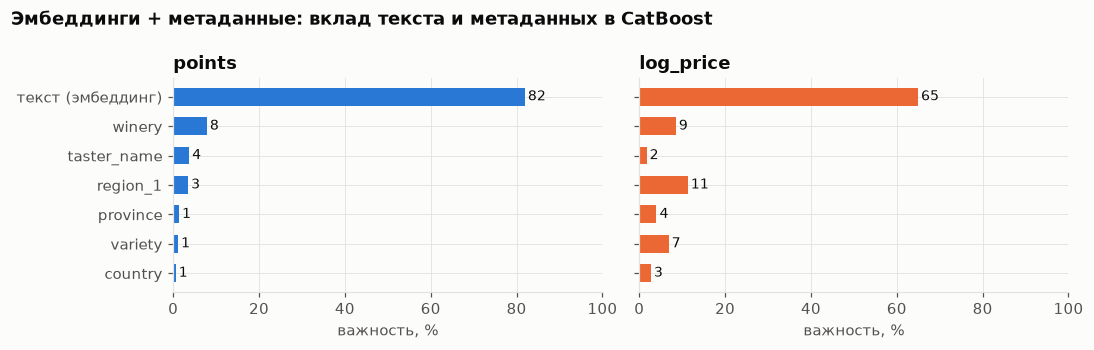

,points,log_price
country,0.6,2.7
variety,1.1,6.8
province,1.4,4.0
region_1,3.5,11.3
taster_name,3.7,1.7
winery,7.8,8.5
текст (эмбеддинг),81.9,64.9


In [7]:
imp = {}
for t in TARGETS:
    fi = tm_models[t].get_feature_importance(prettified=True).set_index("Feature Id")["Importances"]
    is_meta = fi.index.isin(META_COLS)
    imp[t] = pd.concat([pd.Series({"текст (эмбеддинг)": fi[~is_meta].sum()}), fi[is_meta]])
imp = pd.DataFrame(imp).sort_values(POINTS_COL)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, t, c in zip(axes, TARGETS, (MAIN, PALETTE[1])):
    bars = ax.barh(imp.index, imp[t], color=c, height=0.6)
    ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=9)
    ax.set_title(t)
    ax.set_xlabel("важность, %")
    ax.set_xlim(0, 100)
fig.suptitle("Эмбеддинги + метаданные: вклад текста и метаданных в CatBoost", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "emb_meta_importance")
plt.show()
imp.round(1)

## 5. Сводка с бейзлайнами

In [8]:
EXPS = ["mean", "meta_catboost", "tfidf_ridge", "emb_ridge", "emb_catboost", "emb_meta_catboost"]
LABELS = ["среднее", "метаданные\n+ CatBoost", "TF-IDF\n+ Ridge", "эмбеддинги\n+ Ridge",
          "эмбеддинги\n+ CatBoost", "эмбеддинги\n+ мета + CatBoost"]
for t in TARGETS:
    print(t)
    display(results_table(t).loc[EXPS, ["RMSE", "MAE", "R2"]].round(3))

points


metric,RMSE,MAE,R2
experiment,,,
mean,3.100,2.539,-0.000
meta_catboost,2.207,1.739,0.493
tfidf_ridge,1.662,1.309,0.713
emb_ridge,1.941,1.539,0.608
emb_catboost,1.914,1.512,0.619
emb_meta_catboost,1.638,1.283,0.721


log_price


metric,RMSE,MAE,R2
experiment,,,
mean,0.659,0.527,-0.000
meta_catboost,0.378,0.275,0.672
tfidf_ridge,0.474,0.363,0.483
emb_ridge,0.512,0.396,0.397
emb_catboost,0.492,0.379,0.444
emb_meta_catboost,0.363,0.270,0.697


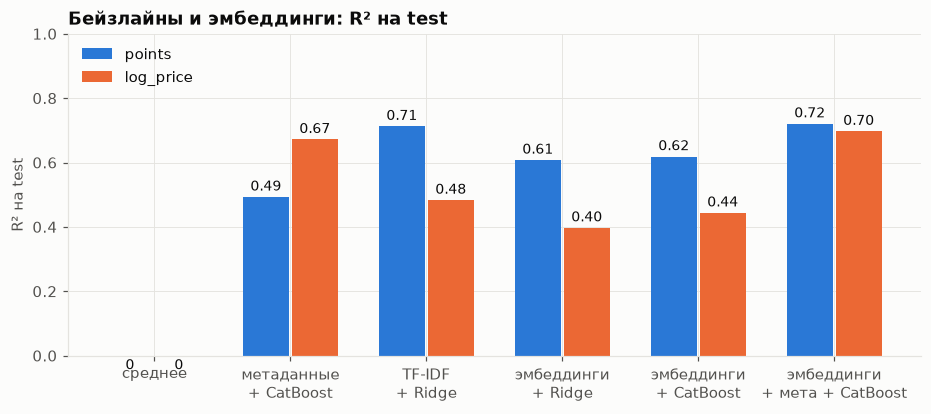

In [ ]:
x = np.arange(len(EXPS))
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, (t, c) in enumerate(zip(TARGETS, (MAIN, PALETTE[1]))):
    r2 = results_table(t).loc[EXPS, "R2"].values
    bars = ax.bar(x + (i - 0.5) * 0.36, r2, width=0.34, color=c, label=t)
    ax.bar_label(bars, labels=[f"{v:.2f}" if abs(v) >= 0.005 else "0" for v in r2], padding=2, fontsize=9)
ax.set_xticks(x, LABELS)
ax.set_ylabel("R² на test")
ax.set_ylim(0, 1)
ax.set_title("Бейзлайны и эмбеддинги: R² на test")
ax.legend(loc="upper left")
save(fig, "embeddings_r2")
plt.show()

## 6. Выводы

| | points RMSE | points $R^2$ | log(price) MAE | log(price) $R^2$ |
|---|---|---|---|---|
| метаданные + CatBoost | 2.21 | 0.49 | 0.275 | 0.67 |
| TF-IDF + Ridge | 1.66 | 0.71 | 0.363 | 0.48 |
| эмбеддинги + Ridge | 1.94 | 0.61 | 0.396 | 0.40 |
| эмбеддинги + CatBoost | 1.91 | 0.62 | 0.379 | 0.44 |
| эмбеддинги + метаданные + CatBoost | **1.64** | **0.72** | **0.270** | **0.70** |

**Замороженные эмбеддинги хуже TF-IDF.** Только по тексту $R^2$ по оценке 0.61–0.62 против 0.71 у TF-IDF + Ridge, по цене 0.40–0.44 против 0.48.
`all-mpnet-base-v2` обучен на поиск похожих по смыслу текстов: он хорошо понимает, *о чём* отзыв (красное вино, танины, ягоды),
но сглаживает отдельные оценочные слова (*stunning, thin, drink now*), а именно они несут сигнал о баллах. TF-IDF держит каждое такое слово отдельным признаком.

**Нелинейная модель почти не помогает.** CatBoost поверх эмбеддингов лишь немного лучше Ridge (+0.01 $R^2$ по оценке, +0.05 по цене):
информация, которой нет в векторе, моделью не восстанавливается. Значит, ограничение в представлении текста, а не в регрессоре.

**Текст и метаданные дополняют друг друга.** Модель с обоими источниками лучшая по обоим таргетам, хотя её текстовая часть слабее TF-IDF:
- по оценке $R^2$ 0.62 → 0.72: метаданные добавляют 0.10, в основном за счёт `winery` и `taster_name` (репутация производителя и личная шкала дегустатора);
- по цене $R^2$ 0.44 → 0.70: и лучше, чем одни метаданные (0.67), то есть текст добавляет к происхождению вина небольшой, но реальный сигнал.

**Вклад признаков** (суммарная важность CatBoost): на текст приходится 82% для оценки и 65% для цены.
Для цены заметную долю забирают `region_1`, `winery` и `variety`, что согласуется с бейзлайном на метаданных.